In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def read_image(path):
    img = cv2.imread(path)
    return img

def plot_image(img, title="Image", is_black_and_white=False):
    if is_black_and_white:
        plt.imshow(img, cmap='gray')
    else:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img_rgb)
    plt.title(title)
    plt.axis('off')
    plt.show()

## Investigar una aplicación de erosión en procesamiento de imágenes e implementarlo en 

### Respuesta

Una de las aplicaciones de la erosion en la industria puede ser la lectura de codigos de barra, muchas veces se tratan de leer mientras los articulos estan en una banda transportadora y las imagenes pueden contener ruido por el movimiento o tener errores de impresion como linesas horizontales que dificultan la lectura. El procedimiento para reparar es primero binarizar y despues aplicacion erosion para separar de mejor manera las barras. El elemento que se usa es un elemento estructurante de 1 pixel por 10 de ancho, por ejemplo.

Referencia: Payne, M. (2021, 23 de febrero). 3 image processing techniques for building enterprise level 1D & 2D barcode scanning software. DEV Community. https://dev.to/mattpayne/3-image-processing-techniques-for-building-enterprise-level-1d-2d-barcode-scanning-software-413f

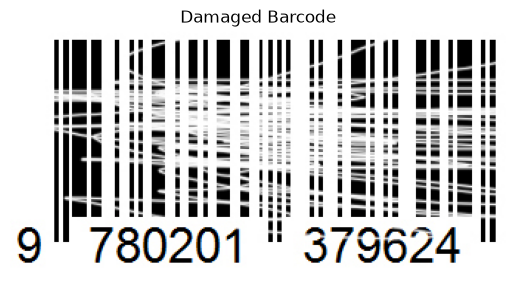

In [3]:
codebar = read_image("data/damaged_code_bar.jpg")
plot_image(codebar, title="Damaged Barcode")

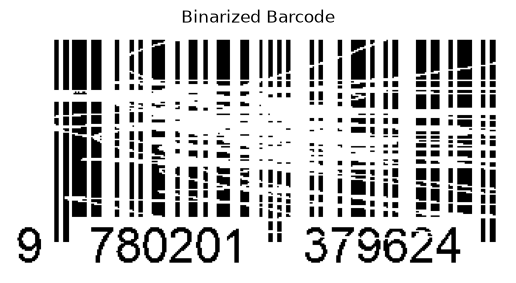

In [4]:
# Binarization
binr = cv2.cvtColor(codebar, cv2.COLOR_BGR2GRAY)
binarize = cv2.threshold(binr, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
plot_image(binarize, title="Binarized Barcode")

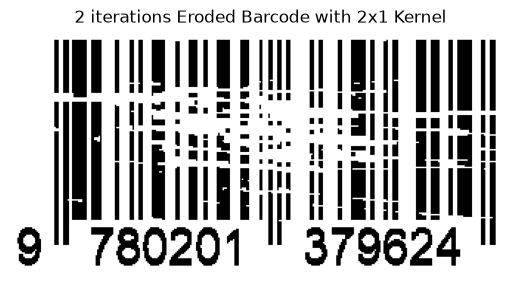

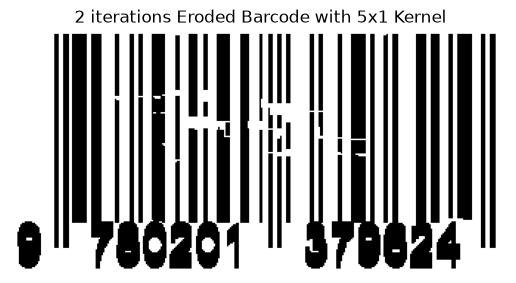

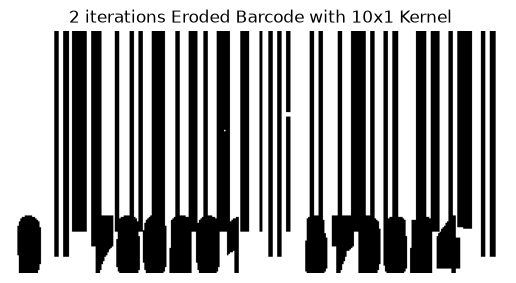

In [5]:
# erode with different kernel sizes  and differnt iterations in a single figure the kernels vertical size 1xN.
kernel_sizes = [2, 5, 10]
eroded_images = []
for k in kernel_sizes:
    kernel = np.ones((k, 1), np.uint8)
    eroded = cv2.erode(binarize, kernel, iterations=2)
    eroded_images.append(eroded)
    plot_image(eroded, title=f" 2 iterations Eroded Barcode with {k}x1 Kernel")

## Investigar una aplicación de dilatación en procesamiento de imágenes e implementarlo en Colab

### Respuesta

En la manufactura de circuitos electricos requerimos de herramientas para poder detecar de manera sencilla errores en las conexiones de los circuitos impresos (PCBs). El uso de la dilatacion es una herramienta poderosa para eso, ya qua ayuda a incementar el tamanio de erroes e identificarlos de manera mas precisa.

Referencia: Park, J.-H., Kim, Y.-S., Seo, H., & Cho, Y.-J. (2023). Analysis of training deep learning models for PCB defect detection. Sensors, 23(5), 2766. https://doi.org/10.3390/s23052766

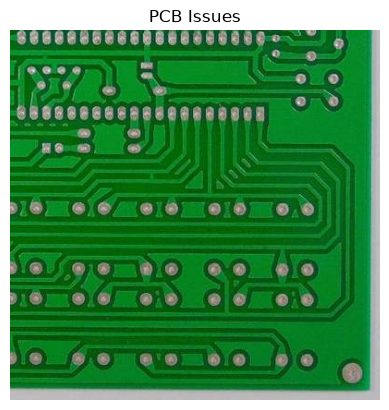

In [6]:
pcb = read_image('data/pcb_issues.jpg')
plot_image(pcb, title="PCB Issues")

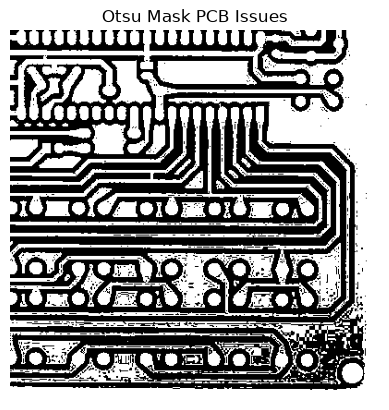

In [22]:
# Create an Otsu mask
binr = cv2.cvtColor(pcb, cv2.COLOR_BGR2GRAY)
otsu_threshold, binarize = cv2.threshold(binr, 80, 255, cv2.THRESH_BINARY )
plot_image(binarize, title="Otsu Mask PCB Issues")

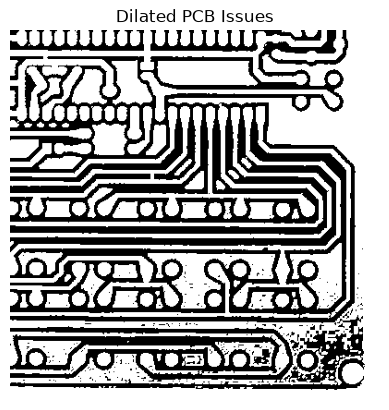

In [23]:
#dilate
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (2,2))
dilated = cv2.dilate(binarize, kernel, iterations=1)
plot_image(dilated, title="Dilated PCB Issues")

## Investigar una aplicación de opening y closing e implementalo en Google Colab

Para el caso de openeing un caso interesante es en plantas automatizadas para empaquetar frutas, como cerezas, manzanas o uvas. Las frutas deben de ser clasificadas por tamanio, calidad, etc. Sin embargo, estas vienen acompaniadas de tallos. Al usar erosion, quitamos los tallos para solo quedarnos las frutas, y para regresar las frutas a sus tamnios reales, aplicamos dilatacion.

Para el closing, una aplicacion es la identificacion rapida de placas de automoviles para multas o en estacionamientos. Al momento de que se toma la imagen, el sistema debe de ser capaz de rapidamente identificar y leer la placa, sin embargo, la parrilla, la defensa, introducen demasiado ruido. Al aplicar dilatacion al inicio lo que hace es saturar la placa con los numeros y se convierte en un bloque de un solo color blanco, la dilatacion despues regresa el rectangulo a su tamanio original. Haciendo facil el encontrar la placa.

Referencias:
Kasaei, S. M., & Monadjemi, S. A. (2009). A novel morphological method for detection and recognition of vehicle license plates. American Journal of Applied Sciences, 6(12), 2066–2070. https://doi.org/10.3844/ajassp.2009.2066.2070


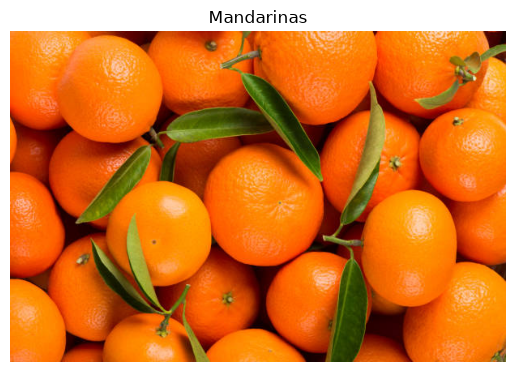

In [39]:
#Opening
mandarinas = read_image('data/mandas.jpg')
plot_image(mandarinas, title="Mandarinas")

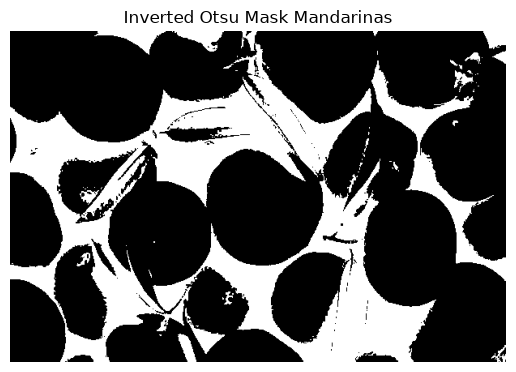

In [41]:
# Create and invert an Otsu mask for opening
binr_mandarinas = cv2.cvtColor(mandarinas, cv2.COLOR_BGR2GRAY)
otsu_threshold_mandarinas, binarize_mandarinas = cv2.threshold(binr_mandarinas, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
binarize_mandarinas = cv2.bitwise_not(binarize_mandarinas)
plot_image(binarize_mandarinas, title="Inverted Otsu Mask Mandarinas")

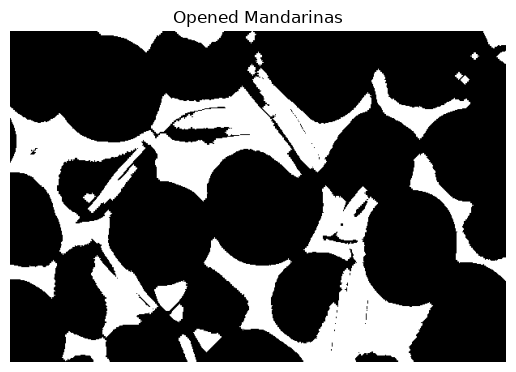

In [51]:
#opening
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (5,5))
opened_mandarinas = cv2.morphologyEx(binarize_mandarinas, cv2.MORPH_OPEN, kernel, iterations=2)
plot_image(opened_mandarinas, title="Opened Mandarinas")

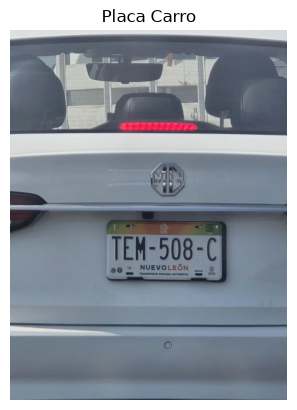

In [12]:
#Closing
placa = read_image('data/placa_carro.webp')
plot_image(placa, title="Placa Carro")

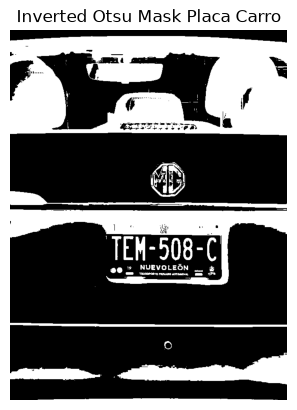

In [29]:
# Create and invert an Otsu mask for closing
gray_placa = cv2.cvtColor(placa, cv2.COLOR_BGR2GRAY)
otsu_threshold_placa, binarize_placa = cv2.threshold(gray_placa, 110, 255, cv2.THRESH_BINARY)
binarize_placa = cv2.bitwise_not(binarize_placa)
plot_image(binarize_placa, title="Inverted Otsu Mask Placa Carro")

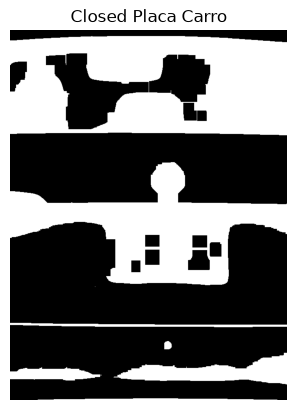

In [31]:
#Closing
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
closed_placa = cv2.morphologyEx(binarize_placa, cv2.MORPH_CLOSE, kernel, iterations=5)
plot_image(closed_placa, title="Closed Placa Carro")